# AI Trust Insights — Data Preprocessing & Analysis

project demonstrating core techniques for exploring, cleaning, sampling, transforming, and analyzing AI trust data. The feature selection and PCA examples are exploratory rather than validated predictive models.

## 1. Data Exploration

Inspect the dataset structure, data quality, numerical distributions, outliers, and relationships before preprocessing.

### Import Libraries

In [ ]:
import pandas as pd               # Data manipulation and analysis
import numpy as np                # Numerical operations
import seaborn as sns             # Statistical visualizations
import matplotlib.pyplot as plt   # Charts and plotting

sns.set_theme(style="whitegrid")

### Load the Dataset

In [ ]:
# Load the dataset
df_original = pd.read_csv("/content/ai_skepticism_dataset.csv")

# Create a copy for preprocessing
df = df_original.copy()

# Display the first five rows
df.head()

,ai_model_name,query_category,ai_confidence_percentage,response_character_count,has_cited_sources,contains_hedging_words,includes_disclaimer,answer_detail_level,respondent_age_bracket,education_level,...,urgency_level,belief_alignment_status,subject_matter_expertise,trust_score_out_of_10,performed_fact_check,fact_check_method_used,verification_duration_mins,answer_accuracy_percentage,trust_calibration_valid,user_skepticism_category
0,Claude,math_calculation,93.23,527,True,False,False,Moderate,45-54,Bachelors,...,Low,False,False,10.0,True,Google Search,10.7,80.15,True,Moderate Trust
1,Llama,recipe_cooking,84.47,581,False,False,False,Specific,55-64,PhD,...,NaN,False,True,7.9,True,Asked Expert,44.3,92.33,True,Skeptical
2,Claude,general_knowledge,69.82,484,True,True,False,Very Specific,35-44,High School,...,NaN,True,False,8.6,True,Consulted Documentation,37.5,67.32,True,Moderate Trust
3,Claude,creative_writing,79.61,73,True,True,False,Specific,45-54,Professional,...,NaN,NaN,False,8.9,True,Checked Official Source,22.7,73.12,True,Moderate Trust
4,Claude,creative_writing,67.71,146,False,True,False,Vague,55-64,Masters,...,NaN,True,True,9.0,True,Academic Paper,43.7,81.05,True,Moderate Trust


### Dataset Structure

Use `head()`, `info()`, and `describe()` to inspect records, column types, and numerical summary statistics.

In [ ]:
# Display dataset structure and column information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ai_model_name               1000 non-null   object 
 1   query_category              1000 non-null   object 
 2   ai_confidence_percentage    1000 non-null   float64
 3   response_character_count    1000 non-null   int64  
 4   has_cited_sources           1000 non-null   bool   
 5   contains_hedging_words      1000 non-null   bool   
 6   includes_disclaimer         1000 non-null   bool   
 7   answer_detail_level         1000 non-null   object 
 8   respondent_age_bracket      1000 non-null   object 
 9   education_level             1000 non-null   object 
 10  digital_literacy_score      1000 non-null   object 
 11  ai_familiarity_level        1000 non-null   object 
 12  decision_importance         1000 non-null   object 
 13  urgency_level               779 no

In [ ]:
# summary statistics for numerical columns
df.describe()

,ai_confidence_percentage,response_character_count,trust_score_out_of_10,verification_duration_mins,answer_accuracy_percentage
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,72.006790,429.022000,7.905000,14.840000,69.982020
std,14.663334,221.644937,1.766866,15.182336,18.176782
min,40.520000,50.000000,1.800000,0.000000,19.420000
25%,60.570000,239.500000,6.700000,0.000000,58.570000
50%,74.235000,423.000000,8.200000,11.050000,72.080000
75%,83.862500,629.000000,9.500000,28.200000,83.140000
max,98.660000,799.000000,10.000000,45.000000,100.000000


### Data Quality Checks

Check for duplicate records and missing values before cleaning.

In [ ]:
# Check number of duplicate rows
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [ ]:
missing_counts = df.isna().sum()
missing_counts[missing_counts > 0]

,0
urgency_level,221
belief_alignment_status,342
fact_check_method_used,372


### Outlier Detection

Boxplots and the IQR rule identify potentially unusual observations. Outliers are retained because extreme trust and accuracy values may be meaningful.

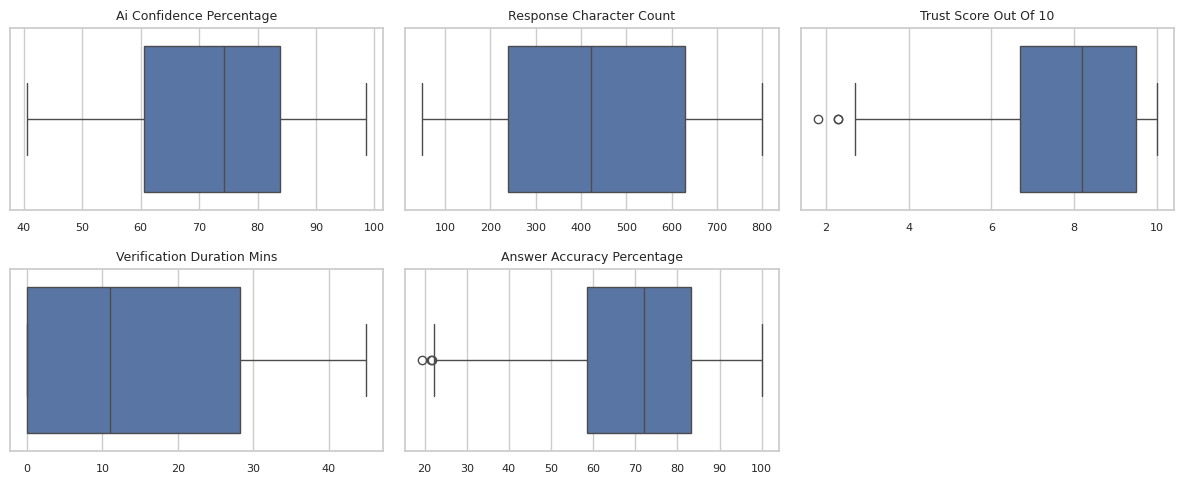

In [ ]:
outlier_columns = [
    "ai_confidence_percentage",
    "response_character_count",
    "trust_score_out_of_10",
    "verification_duration_mins",
    "answer_accuracy_percentage"
]

fig, axes = plt.subplots(2, 3, figsize=(12, 5))
axes = axes.flatten()

for i, col in enumerate(outlier_columns):
    sns.boxplot(
        x=df[col],
        ax=axes[i],
    )

    axes[i].set_title(
        col.replace("_", " ").title(),
        fontsize=9
    )
    axes[i].set_xlabel("")
    axes[i].tick_params(axis="x", labelsize=8)

for ax in axes[len(outlier_columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:
iqr_columns = [
    "trust_score_out_of_10",
    "answer_accuracy_percentage"
]

outlier_summary = []

for col in iqr_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_mask = (
        (df[col] < lower) |
        (df[col] > upper)
    )
    outlier_summary.append({
        "column": col,
        "lower": lower,
        "upper": upper,
        "outlier_count": outlier_mask.sum()
    })

outlier_summary = pd.DataFrame(outlier_summary)
outlier_summary

,column,lower,upper,outlier_count
0,trust_score_out_of_10,2.500,13.700,3
1,answer_accuracy_percentage,21.715,119.995,3


### Numerical Distributions

Histograms and skewness summarize the distribution of numerical variables.

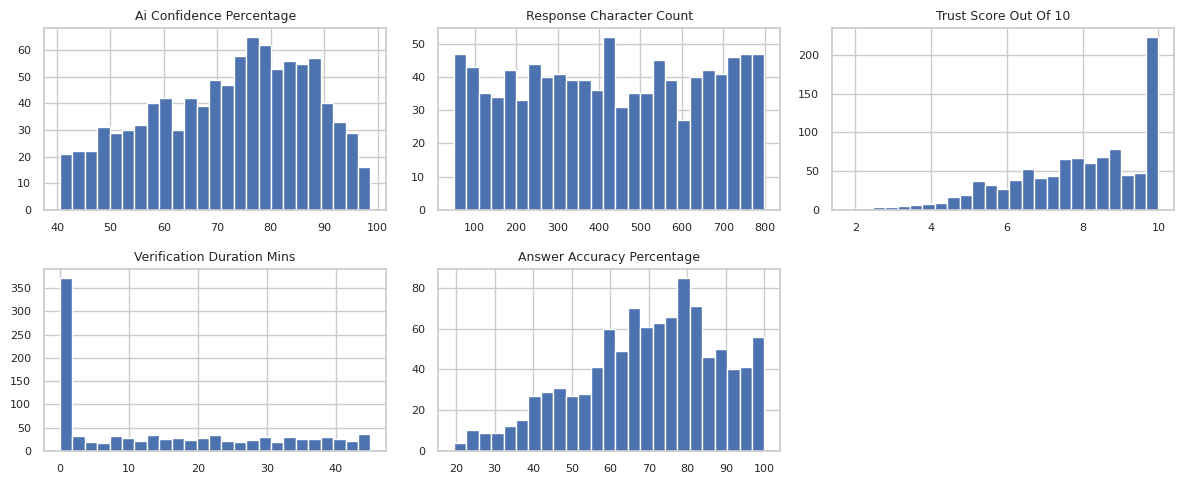

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(12, 5))
axes = axes.flatten()

for i, col in enumerate(outlier_columns):
    axes[i].hist(df[col].dropna(), bins=25, edgecolor="white")

    axes[i].set_title(
        col.replace("_", " ").title(),
        fontsize=9
    )
    axes[i].set_xlabel("")
    axes[i].tick_params(labelsize=8)

for ax in axes[len(outlier_columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:
skewness_summary = (
    df[outlier_columns]
    .skew()
    .round(2)
    .rename("skewness")
    .to_frame()
)

skewness_summary

,skewness
ai_confidence_percentage,-0.31
response_character_count,-0.01
trust_score_out_of_10,-0.66
verification_duration_mins,0.53
answer_accuracy_percentage,-0.45


### Correlation Analysis

A Pearson correlation heatmap explores linear associations between numerical variables.

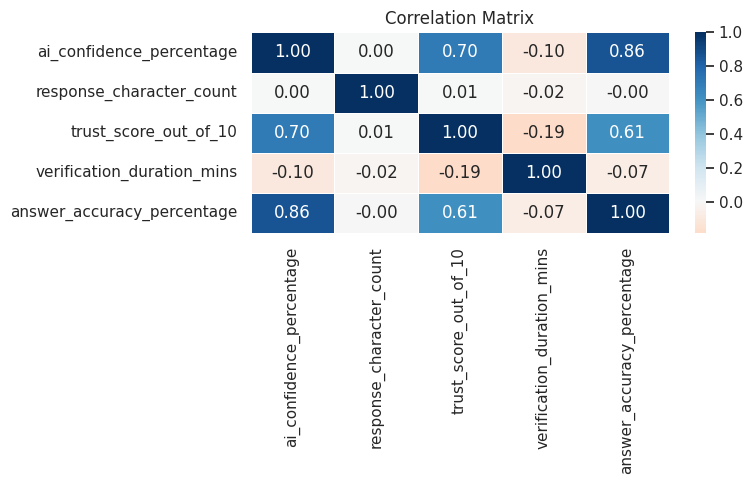

In [ ]:
corr_matrix = df.select_dtypes(include="number").corr()

plt.figure(figsize=(8, 5))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

### Confidence and Trust

A scatter plot visualizes the relationship between reported AI confidence and user trust in the full dataset.

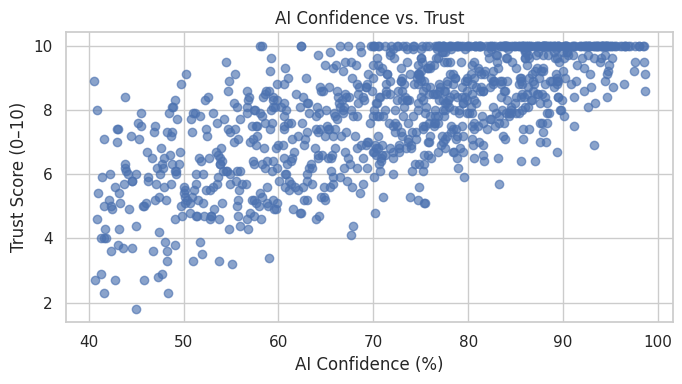

In [ ]:
plt.figure(figsize=(7, 4))
plt.scatter(
    df["ai_confidence_percentage"],
    df["trust_score_out_of_10"],
    alpha=0.65
)
plt.title("AI Confidence vs. Trust")
plt.xlabel("AI Confidence (%)")
plt.ylabel("Trust Score (0–10)")
plt.tight_layout()
plt.show()

## 2. Data Cleaning

Missing categorical values are labeled `Unknown`.

### Missing Value Handling

In [ ]:
categorical_cols = [
    "urgency_level",
    "belief_alignment_status",
    "fact_check_method_used"
]

df[categorical_cols] = df[categorical_cols].fillna("Unknown")

In [ ]:
remaining_missing = df.isna().sum()
print("Total remaining missing values:", remaining_missing.sum())
remaining_missing[remaining_missing > 0]

Total remaining missing values: 0


,0


## 3. Data Sampling & Summarization

This section demonstrates randomly selecting query categories and summarizing the resulting records.

### Random Category-Based Sampling

`random.sample()` selects 10 of the 12 query categories. All records in those categories are retained, and seed `42` makes the selection reproducible.

In [ ]:
import random

random.seed(42)
query_categories = df["query_category"].unique()
random_categories = random.sample(list(query_categories), 10)

print("Selected query categories:", random_categories)

Selected query categories: ['legal_advice', 'recipe_cooking', 'math_calculation', 'technical_coding', 'creative_writing', 'scientific_facts', 'medical_advice', 'opinion_based', 'factual_historical', 'general_knowledge']


In [ ]:
data_sample = df[df["query_category"].isin(random_categories)].copy()
print("Sample records:", len(data_sample))

Sample records: 846


### Sample Composition

`value_counts()` displays category and model frequencies, while `nunique()` counts distinct groups.

In [ ]:
data_sample["query_category"].value_counts().rename("records")

,records
query_category,
recipe_cooking,101
scientific_facts,96
math_calculation,92
opinion_based,87
medical_advice,84
technical_coding,83
general_knowledge,82
legal_advice,81
factual_historical,77


In [ ]:
data_sample["ai_model_name"].value_counts().rename("records")

,records
ai_model_name,
Gemini,161
Llama,145
Claude,142
ChatGPT-3.5,141
Mistral,129
GPT-4,128


In [ ]:
sample_summary = pd.Series({
    "sample_records": len(data_sample),
    "query_categories": data_sample["query_category"].nunique(),
    "ai_models": data_sample["ai_model_name"].nunique()
}, name="count")

sample_summary

,count
sample_records,846
query_categories,10
ai_models,6


### Grouped Trust Summary

`groupby()` calculates the mean trust score for each AI model within the selected categories.

In [ ]:
model_trust = (
    data_sample.groupby("ai_model_name")["trust_score_out_of_10"]
    .mean()
    .reset_index(name="avg_trust")
)

model_trust

,ai_model_name,avg_trust
0,ChatGPT-3.5,7.890780
1,Claude,8.408451
2,GPT-4,8.314844
3,Gemini,8.014907
4,Llama,7.833793
5,Mistral,8.216279


## 4. Feature Scaling & Encoding

Compare numerical scaling methods and encode categorical features without changing the cleaned dataframe.

### Numerical Feature Scaling

`MinMaxScaler` scales values to [0, 1], while `RobustScaler` uses the median and IQR to reduce sensitivity to outliers. Both are stored separately for comparison; `StandardScaler` is used later specifically for RFE and PCA.

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaling_columns = [
    "ai_confidence_percentage",
    "response_character_count",
    "trust_score_out_of_10",
    "verification_duration_mins",
    "answer_accuracy_percentage"
]

minmax_scaler = MinMaxScaler()

df_minmax = pd.DataFrame(
    minmax_scaler.fit_transform(df[scaling_columns]),
    columns=scaling_columns,
    index=df.index
)

df_minmax.head()

,ai_confidence_percentage,response_character_count,trust_score_out_of_10,verification_duration_mins,answer_accuracy_percentage
0,0.906605,0.636849,1.000000,0.237778,0.753661
1,0.755934,0.708945,0.743902,0.984444,0.904815
2,0.503956,0.579439,0.829268,0.833333,0.594440
3,0.672343,0.030708,0.865854,0.504444,0.666418
4,0.467664,0.128171,0.878049,0.971111,0.764830


In [ ]:
from sklearn.preprocessing import RobustScaler

robust_scaler = RobustScaler()

df_robust = pd.DataFrame(
    robust_scaler.fit_transform(df[scaling_columns]),
    columns=scaling_columns,
    index=df.index
)

df_robust.head()

,ai_confidence_percentage,response_character_count,trust_score_out_of_10,verification_duration_mins,answer_accuracy_percentage
0,0.815499,0.267009,0.642857,-0.012411,0.328449
1,0.439412,0.405648,-0.107143,1.179078,0.824176
2,-0.189546,0.156611,0.142857,0.937943,-0.193732
3,0.230761,-0.898588,0.250000,0.413121,0.042328
4,-0.280133,-0.711168,0.285714,1.157801,0.365079


### Categorical Encoding

Category counts are reviewed before `get_dummies()` converts categorical values into one-hot indicators. The encoded result is stored separately.

In [ ]:
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

category_summary = pd.DataFrame({
    "column": categorical_columns,
    "unique_categories": [df[col].nunique() for col in categorical_columns]
})

category_summary

,column,unique_categories
0,ai_model_name,6
1,query_category,12
2,answer_detail_level,4
3,respondent_age_bracket,6
4,education_level,5
5,digital_literacy_score,4
6,ai_familiarity_level,5
7,decision_importance,4
8,urgency_level,4
9,belief_alignment_status,3


In [ ]:
df_encoded = pd.get_dummies(
    df,
    columns=categorical_columns,
    dtype=int
)

df_encoded.head()

,ai_confidence_percentage,response_character_count,has_cited_sources,contains_hedging_words,includes_disclaimer,subject_matter_expertise,trust_score_out_of_10,performed_fact_check,verification_duration_mins,answer_accuracy_percentage,...,fact_check_method_used_Checked Official Source,fact_check_method_used_Consulted Documentation,fact_check_method_used_Cross-referenced Multiple AIs,fact_check_method_used_Google Search,fact_check_method_used_Personal Testing,fact_check_method_used_Unknown,user_skepticism_category_Blind Trust,user_skepticism_category_Highly Skeptical,user_skepticism_category_Moderate Trust,user_skepticism_category_Skeptical
0,93.23,527,True,False,False,False,10.0,True,10.7,80.15,...,0,0,0,1,0,0,0,0,1,0
1,84.47,581,False,False,False,True,7.9,True,44.3,92.33,...,0,0,0,0,0,0,0,0,0,1
2,69.82,484,True,True,False,False,8.6,True,37.5,67.32,...,0,1,0,0,0,0,0,0,1,0
3,79.61,73,True,True,False,False,8.9,True,22.7,73.12,...,1,0,0,0,0,0,0,0,1,0
4,67.71,146,False,True,False,True,9.0,True,43.7,81.05,...,0,0,0,0,0,0,0,0,1,0


## 5. Feature Selection & Dimensionality Reduction

RFE selects existing numerical predictors, whereas PCA creates new components to represent the predictors in fewer dimensions. These examples use the complete dataset for exploration, not model validation.

In [ ]:
df_fe = df.copy()

### Recursive Feature Elimination (RFE)

Linear-regression-based RFE selects three standardized numerical predictors of `answer_accuracy_percentage`. The target is excluded from the predictor matrix.

In [ ]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

X = df_fe.select_dtypes(include="number").drop(
    columns="answer_accuracy_percentage")
y = df_fe["answer_accuracy_percentage"]

X_scaled = pd.DataFrame(
    StandardScaler().fit_transform(X),
    columns=X.columns,
    index=X.index)

rfe = RFE(
    estimator=LinearRegression(),
    n_features_to_select=3)

rfe.fit(X_scaled, y)

rfe_results = pd.DataFrame({
    "Feature": X.columns,
    "Selected": rfe.support_,
    "Rank": rfe.ranking_})

rfe_results.sort_values("Rank")

,Feature,Selected,Rank
0,ai_confidence_percentage,True,1
2,trust_score_out_of_10,True,1
3,verification_duration_mins,True,1
1,response_character_count,False,2


### Principal Component Analysis (PCA)

PCA is fitted to standardized predictors, excluding answer accuracy. Explained variance indicates how much variation the components capture.

In [ ]:
from sklearn.decomposition import PCA

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

pca_summary = pd.DataFrame({
    "Component": range(1, len(explained_variance) + 1),
    "Explained Variance": explained_variance,
    "Cumulative Variance": cumulative_variance
})

pca_summary

,Component,Explained Variance,Cumulative Variance
0,1,0.440005,0.440005
1,2,0.251260,0.691266
2,3,0.236121,0.927387
3,4,0.072613,1.000000


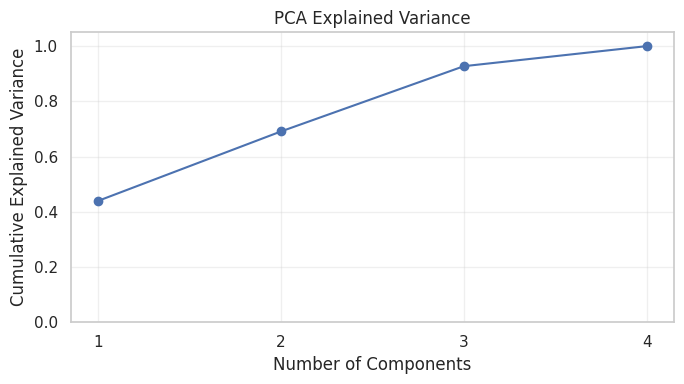

In [ ]:
plt.figure(figsize=(7, 4))

plt.plot(
    pca_summary["Component"],
    pca_summary["Cumulative Variance"],
    marker="o"
)

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.xticks(pca_summary["Component"])
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Two-Component PCA

The numerical predictors are reduced to two principal components for visualization. Point colors represent answer accuracy, which is not used to fit PCA.

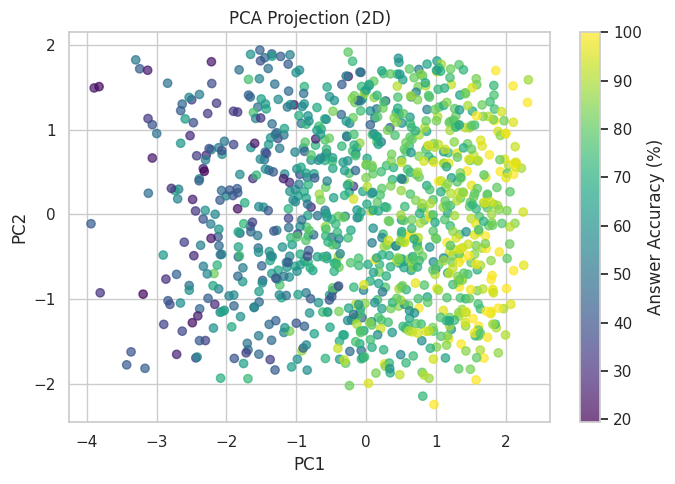

In [ ]:
pca_2d = PCA(n_components=2)

X_pca_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(7, 5))

scatter = plt.scatter(
    X_pca_2d[:, 0],
    X_pca_2d[:, 1],
    c=y,
    cmap="viridis",
    alpha=0.7)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Projection (2D)")
plt.colorbar(scatter, label="Answer Accuracy (%)")
plt.tight_layout()
plt.show()

## 6. Data Reshaping

This section demonstrates basic ways to summarize and reorganize the cleaned dataset:

- **`pivot_table()`** calculates average trust by AI model and query category.
- **`stack()` / `unstack()`** move data between row-index and column layouts.
- **`crosstab()`** counts answer detail levels for each AI model.
- **`cut()`** groups mean trust values into illustrative Low, Medium, and High bands.

### Pivot Table

In [ ]:
pivot_df = pd.pivot_table(
    df,
    values="trust_score_out_of_10",
    index="ai_model_name",
    columns="query_category",
    aggfunc="mean"
).round(2)

pivot_df

query_category,creative_writing,current_events,factual_historical,financial_advice,general_knowledge,legal_advice,math_calculation,medical_advice,opinion_based,recipe_cooking,scientific_facts,technical_coding
ai_model_name,,,,,,,,,,,,
ChatGPT-3.5,8.53,6.09,8.68,5.77,7.72,6.46,9.18,6.91,5.84,8.48,8.72,8.86
Claude,8.40,7.42,8.72,6.53,8.42,7.08,9.28,7.61,6.05,9.23,9.18,9.23
GPT-4,8.96,7.74,9.14,6.75,8.53,6.74,9.54,7.77,5.84,8.59,8.65,8.97
Gemini,7.60,7.58,8.82,5.82,8.57,6.52,9.77,7.24,5.74,8.90,8.23,8.92
Llama,7.63,7.74,8.57,6.54,8.49,6.83,9.53,6.18,6.20,8.59,8.27,9.31
Mistral,7.12,8.08,8.62,5.78,8.07,6.85,9.65,6.96,5.88,8.77,8.56,8.92


### Stack and Unstack

In [ ]:
stacked_df = pivot_df.stack()

unstacked_df = stacked_df.unstack()

display(stacked_df.head(10))
display(unstacked_df.head())

ai_model_name  query_category    
ChatGPT-3.5    creative_writing      8.53
               current_events        6.09
               factual_historical    8.68
               financial_advice      5.77
               general_knowledge     7.72
               legal_advice          6.46
               math_calculation      9.18
               medical_advice        6.91
               opinion_based         5.84
               recipe_cooking        8.48
dtype: float64

query_category,creative_writing,current_events,factual_historical,financial_advice,general_knowledge,legal_advice,math_calculation,medical_advice,opinion_based,recipe_cooking,scientific_facts,technical_coding
ai_model_name,,,,,,,,,,,,
ChatGPT-3.5,8.53,6.09,8.68,5.77,7.72,6.46,9.18,6.91,5.84,8.48,8.72,8.86
Claude,8.40,7.42,8.72,6.53,8.42,7.08,9.28,7.61,6.05,9.23,9.18,9.23
GPT-4,8.96,7.74,9.14,6.75,8.53,6.74,9.54,7.77,5.84,8.59,8.65,8.97
Gemini,7.60,7.58,8.82,5.82,8.57,6.52,9.77,7.24,5.74,8.90,8.23,8.92
Llama,7.63,7.74,8.57,6.54,8.49,6.83,9.53,6.18,6.20,8.59,8.27,9.31


### Crosstabulation

In [ ]:
ct = pd.crosstab(
    df["ai_model_name"],
    df["answer_detail_level"]
)

ct

answer_detail_level,Moderate,Specific,Vague,Very Specific
ai_model_name,,,,
ChatGPT-3.5,39,37,45,39
Claude,40,41,41,49
GPT-4,48,29,34,45
Gemini,53,56,45,36
Llama,39,47,48,31
Mistral,42,33,46,37


### Numerical Binning with `cut()`

The cutoffs below are illustrative thresholds, not validated trust categories.

In [ ]:
creative_levels = pd.cut(
    pivot_df["creative_writing"],
    bins=[0, 7, 8.5, 10],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

pd.DataFrame({
    "average_trust": pivot_df["creative_writing"],
    "trust_level": creative_levels
})

,average_trust,trust_level
ai_model_name,,
ChatGPT-3.5,8.53,High
Claude,8.40,Medium
GPT-4,8.96,High
Gemini,7.60,Medium
Llama,7.63,Medium
Mistral,7.12,Medium
